# TASK 2: UNEMPLOYMENT ANALYSIS WITH PYTHON

**Objective:** To analyse unemployment data in India and understand regional and monthly trends, with a focus on COVID-19.

**Technologies Used:** Python, Pandas, NumPy, Matplotlib, Seaborn and Jupyter Notebook.

**Dataset:** Unemployment in India.csv

## 1. Dataset Loading

The dataset contains information about unemployment rates, estimated employment and labour participation rates across different regions of India.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("Unemployment in India.csv")

# Display first five rows
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 2. Exploratory Data Analysis (EDA)

In this step, we examine the dataset structure, data types, missing values and descriptive statistics. We also convert the Date column into the correct date format.

In [2]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')

# Convert numerical columns into numeric data types
numeric_columns = [
    'Estimated Unemployment Rate (%)',
    'Estimated Employed',
    'Estimated Labour Participation Rate (%)'
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display descriptive statistics
print("\nDescriptive Statistics:")
df.describe()

Dataset Shape: (768, 7)

Column Names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Data Types:
Region                                                str
Date                                       datetime64[us]
Frequency                                             str
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                                  str
dtype: object

Missing Values:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

Descriptive Statistics:


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


In [3]:
# Remove completely empty rows
df = df.dropna(how='all')

# Check updated dataset shape
print("Updated Dataset Shape:", df.shape)

# Check missing values after cleaning
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Updated Dataset Shape: (740, 7)

Missing Values After Cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


### EDA Observations

1. The dataset contains 740 valid records and 7 columns.
2. The dataset covers the period from May 2019 to June 2020.
3. The average unemployment rate is approximately 11.79%.
4. The average labour participation rate is approximately 42.63%.
5. The maximum recorded unemployment rate is 76.74%.
6. No missing values remain after cleaning.

## 3. Region-wise Unemployment Analysis

In this step, we calculate the average unemployment rate for each state and region in India. This helps identify regions with higher and lower unemployment rates.

In [4]:
# Calculate average unemployment rate for each region
region_unemployment = (
    df.groupby('Region')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
)

# Display average unemployment rate by region
print("Average Unemployment Rate by Region:")
region_unemployment

Average Unemployment Rate by Region:


Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64

### Region-wise Analysis Observations

1. Tripura has the highest average unemployment rate of approximately 28.35%.
2. Haryana has the second-highest average unemployment rate of approximately 26.28%.
3. Jharkhand has the third-highest average unemployment rate of approximately 20.59%.
4. Meghalaya has the lowest average unemployment rate of approximately 4.80%.
5. Maharashtra has an average unemployment rate of approximately 7.56%.
6. Unemployment rates vary across different regions of India.

## 4. Monthly Unemployment Analysis

In this step, we calculate the average unemployment rate for each month to understand how unemployment changed over time.

In [5]:
# Extract month and year from the Date column
df['Month'] = df['Date'].dt.to_period('M')

# Calculate monthly average unemployment rate
monthly_unemployment = (
    df.groupby('Month')['Estimated Unemployment Rate (%)'].mean()
)

# Display monthly unemployment rates
print("Monthly Average Unemployment Rate:")
monthly_unemployment

Monthly Average Unemployment Rate:


Month
2019-05     8.874259
2019-06     9.303333
2019-07     9.033889
2019-08     9.637925
2019-09     9.051731
2019-10     9.900909
2019-11     9.868364
2019-12     9.497358
2020-01     9.950755
2020-02     9.964717
2020-03    10.700577
2020-04    23.641569
2020-05    24.875294
2020-06    11.903600
Freq: M, Name: Estimated Unemployment Rate (%), dtype: float64

### Monthly Analysis Observations

1. The average unemployment rate remained around 9% to 10% from May 2019 to February 2020.
2. In March 2020, the rate increased to approximately 10.70%.
3. It increased sharply to approximately 23.64% in April 2020.
4. The highest monthly average was approximately 24.88% in May 2020.
5. In June 2020, the rate decreased to approximately 11.90%.

## 5. Monthly Unemployment Trend Chart

A line chart is used to visualise the monthly average unemployment rate from May 2019 to June 2020.

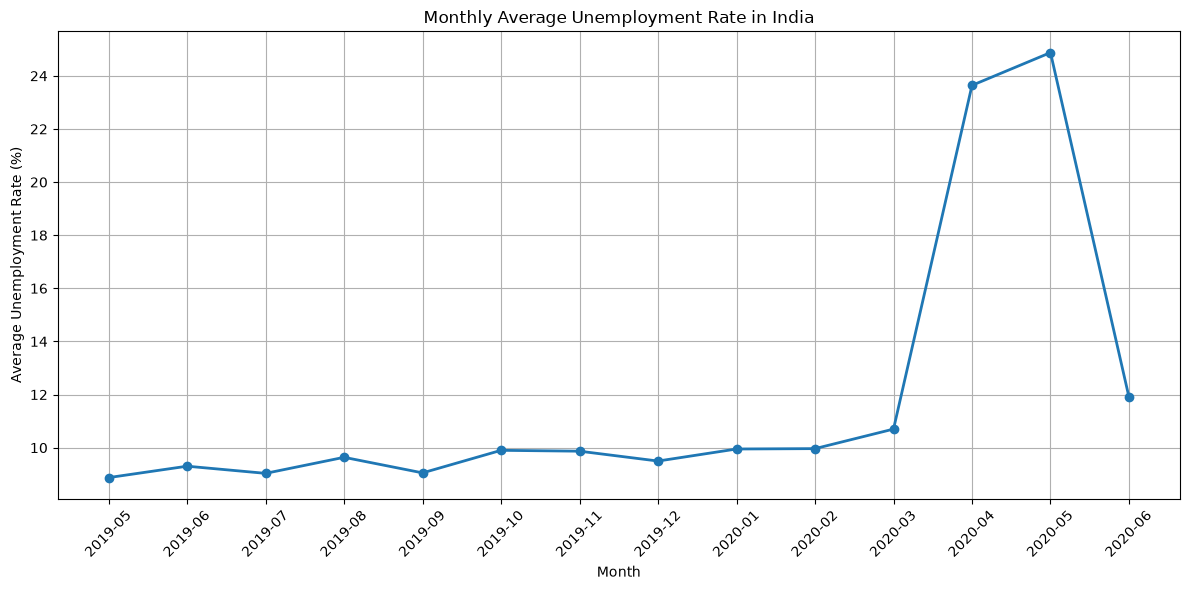

In [6]:
# Plot monthly unemployment rate
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index.astype(str),
    monthly_unemployment.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Average Unemployment Rate in India')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 6. State-wise Unemployment Trend

In this step, we compare unemployment rates across Maharashtra, Uttar Pradesh and West Bengal using a time-series line chart.

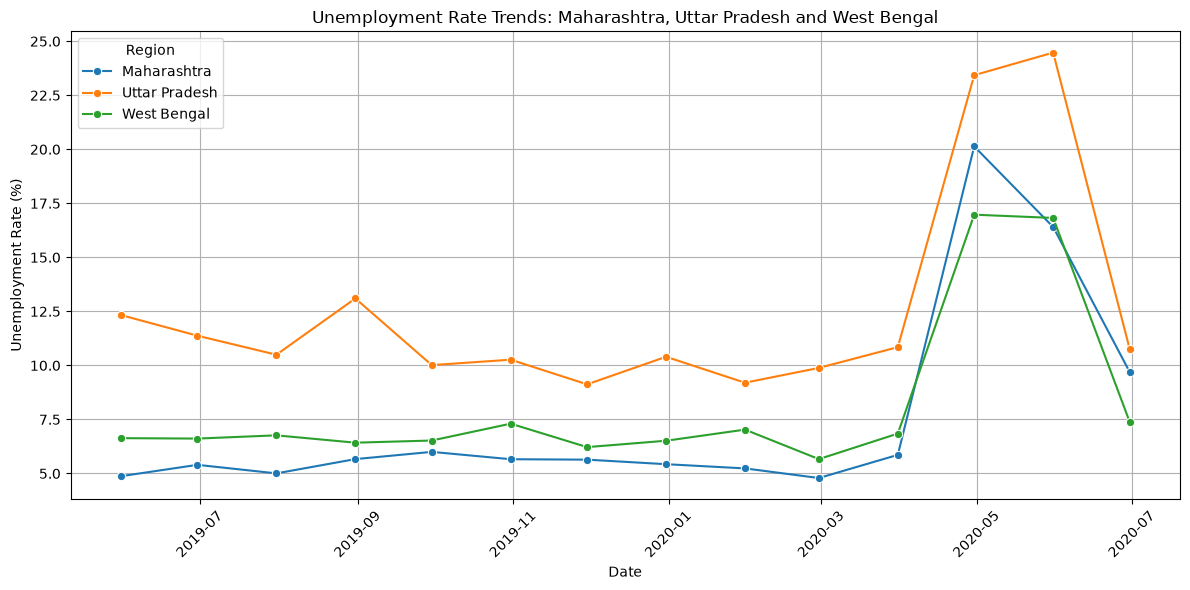

In [7]:
# Select three major states
selected_states = ['Maharashtra', 'Uttar Pradesh', 'West Bengal']

# Filter data for selected states
state_data = df[df['Region'].isin(selected_states)]

# Calculate average unemployment rate for each date and state
state_trends = (
    state_data.groupby(['Date', 'Region'])
    ['Estimated Unemployment Rate (%)']
    .mean()
    .reset_index()
)

# Plot unemployment trends
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_trends,
    x='Date',
    y='Estimated Unemployment Rate (%)',
    hue='Region',
    marker='o'
)

plt.title('Unemployment Rate Trends: Maharashtra, Uttar Pradesh and West Bengal')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 7. Top 10 Regions with Highest Average Unemployment

A bar chart is used to identify and compare the ten regions with the highest average unemployment rates.

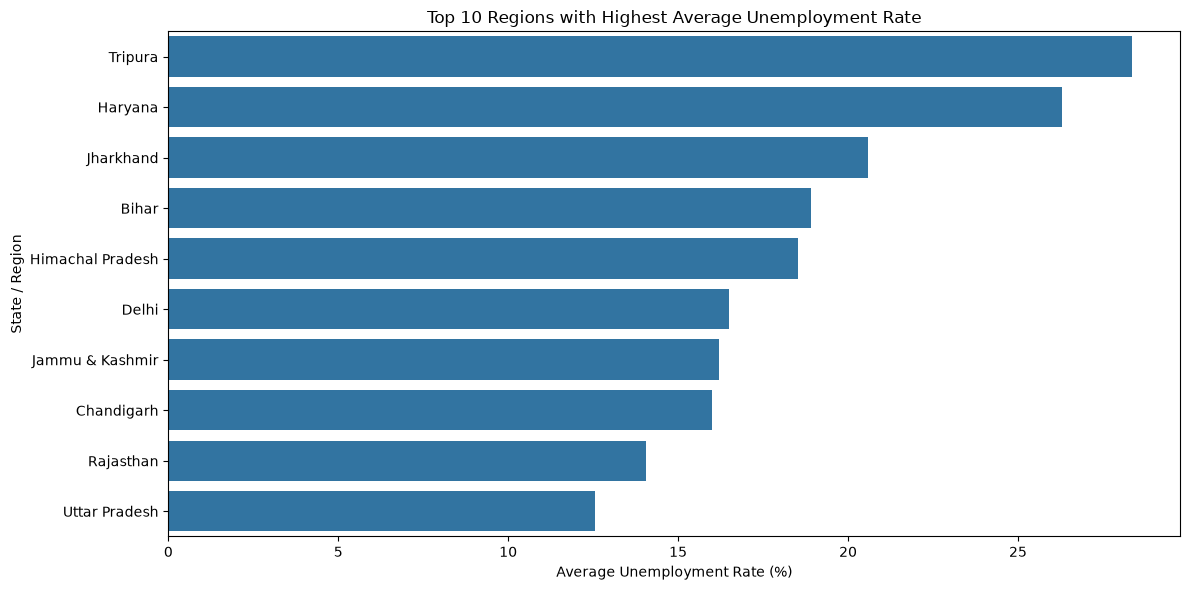

In [8]:
# Calculate average unemployment rate for each region
top_10_states = (
    df.groupby('Region')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_states.values,
    y=top_10_states.index
)

plt.title('Top 10 Regions with Highest Average Unemployment Rate')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('State / Region')
plt.tight_layout()
plt.show()

## 8. Correlation Analysis

Correlation analysis helps us understand the relationship between unemployment, estimated employment and labour participation rates. A heatmap is used to display these relationships.

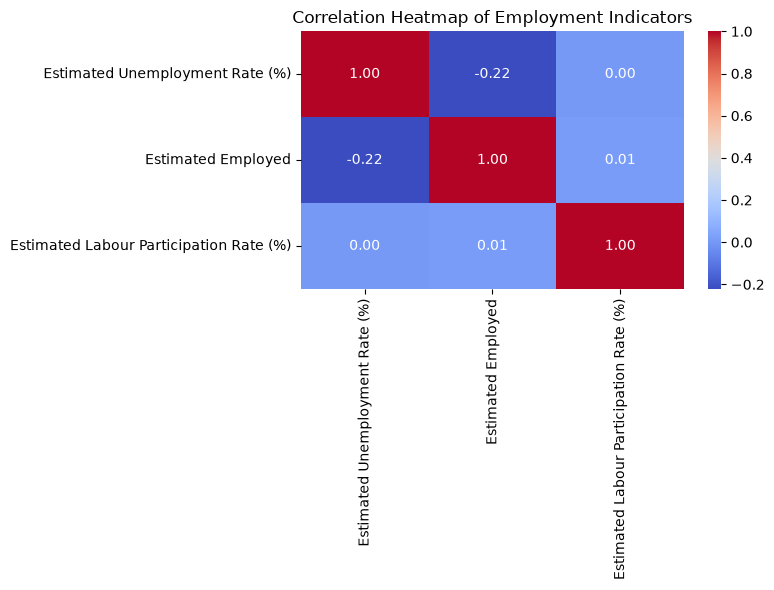

In [9]:
# Select columns for correlation analysis
correlation_data = df[
    [
        'Estimated Unemployment Rate (%)',
        'Estimated Employed',
        'Estimated Labour Participation Rate (%)'
    ]
]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Create correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Employment Indicators')
plt.tight_layout()
plt.show()

## 9. Pre-COVID vs COVID-Period Comparison

In this step, we compare the average unemployment rate before COVID-19 and during the COVID-19 period. March 2020 is used as the starting point of the COVID-19 period for this analysis.

In [10]:
# Divide data into pre-COVID and COVID periods
pre_covid = df[df['Date'] < '2020-03-01']
covid_period = df[df['Date'] >= '2020-03-01']

# Calculate average unemployment rates
pre_covid_avg = pre_covid['Estimated Unemployment Rate (%)'].mean()
covid_avg = covid_period['Estimated Unemployment Rate (%)'].mean()

# Display comparison
print("Pre-COVID Average Unemployment Rate:", round(pre_covid_avg, 2), "%")
print("COVID-Period Average Unemployment Rate:", round(covid_avg, 2), "%")

Pre-COVID Average Unemployment Rate: 9.51 %
COVID-Period Average Unemployment Rate: 17.77 %


### Pre-COVID vs COVID-Period Observations

1. The average unemployment rate before COVID-19 was approximately 9.51%.
2. During the COVID-19 period, the average unemployment rate increased to approximately 17.77%.
3. There was an increase of 8.26 percentage points during the COVID-19 period.
4. The data shows a significant rise in unemployment during the COVID-19 period.
5. This increase may be associated with lockdowns and disruptions to economic activities.

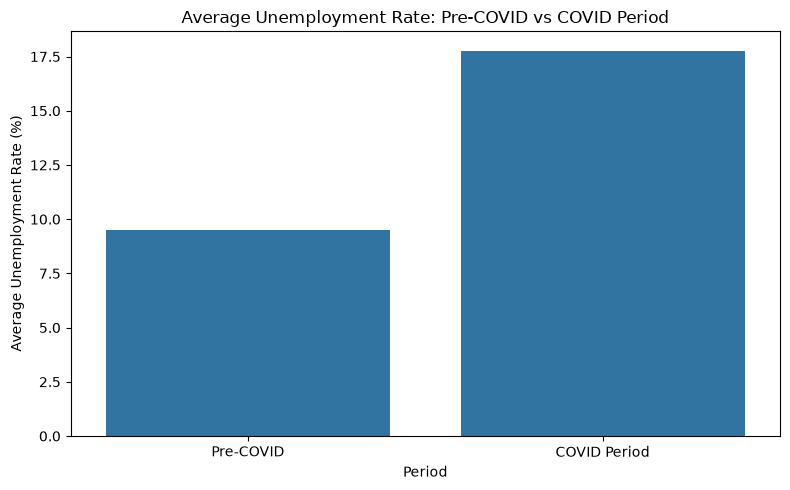

In [11]:
# Compare pre-COVID and COVID-period unemployment rates
periods = ['Pre-COVID', 'COVID Period']
average_rates = [pre_covid_avg, covid_avg]

plt.figure(figsize=(8, 5))

sns.barplot(x=periods, y=average_rates)

plt.title('Average Unemployment Rate: Pre-COVID vs COVID Period')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()

## 10. Conclusion

The analysis of unemployment data in India helped identify regional and monthly unemployment trends.

1. Tripura recorded the highest average unemployment rate among the regions.
2. Meghalaya recorded the lowest average unemployment rate.
3. Unemployment increased sharply during April and May 2020.
4. Maharashtra, Uttar Pradesh and West Bengal showed different unemployment trends over time.
5. The average unemployment rate increased from 9.51% before COVID-19 to 17.77% during the COVID-19 period.
6. The analysis highlights the impact of the COVID-19 period on unemployment in India.

Overall, this project demonstrates how Python libraries such as Pandas, Matplotlib and Seaborn can be used for data analysis and visualisation.